#Warehouse Delivery Graduation Project

## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

## Loading Data

In [2]:
raw = pd.read_csv("warehouse_delivery_raw.csv")

## Inspecting Data

In [4]:
raw.head()

,Order_ID,Order_Date,Delivery_Date,Region,Warehouse,Courier,Order_Value_EGP,Shipping_Cost_EGP,Promised_Days,Delivery_Status,Customer_Rating
0,ORD-10001,2026-01-25,2026-01-26,Manfalut,East Hub,Delta Delivery,849.06,76.15,2,Delivered On Time,3.0
1,ORD-10002,2026-07-28,2026-07-31,Dairut,East Hub,Nile Express,659.65,73.58,2,Delivered Late,4.5
2,ORD-10003,2026-06-26,2026-06-27,Qusiya,Central Warehouse,FastTrack,505.74,83.70,2,Delivered On Time,4.0
3,ORD-10004,2026-04-29,2026-04-30,Dairut,East Hub,Delta Delivery,1257.95,90.66,2,Delivered On Time,3.6
4,ORD-10005,2026-04-27,2026-05-02,Qusiya,East Hub,FastTrack,1059.78,82.49,2,Delivered Late,3.9


In [5]:
print(raw.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1212 entries, 0 to 1211
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Order_ID           1212 non-null   object 
 1   Order_Date         1212 non-null   object 
 2   Delivery_Date      1018 non-null   object 
 3   Region             1212 non-null   object 
 4   Warehouse          1212 non-null   object 
 5   Courier            1198 non-null   object 
 6   Order_Value_EGP    1212 non-null   float64
 7   Shipping_Cost_EGP  1194 non-null   float64
 8   Promised_Days      1212 non-null   int64  
 9   Delivery_Status    1212 non-null   object 
 10  Customer_Rating    1176 non-null   float64
dtypes: float64(3), int64(1), object(7)
memory usage: 104.3+ KB
None


In [6]:
print(raw.isna().sum())

Order_ID               0
Order_Date             0
Delivery_Date        194
Region                 0
Warehouse              0
Courier               14
Order_Value_EGP        0
Shipping_Cost_EGP     18
Promised_Days          0
Delivery_Status        0
Customer_Rating       36
dtype: int64


In [7]:
raw.duplicated().sum()

np.int64(12)

In [8]:
raw.describe().round()

,Order_Value_EGP,Shipping_Cost_EGP,Promised_Days,Customer_Rating
count,1212.0,1194.0,1212.0,1176.0
mean,1200.0,75.0,2.0,4.0
std,668.0,69.0,0.0,1.0
min,120.0,15.0,1.0,2.0
25%,715.0,57.0,1.0,4.0
50%,1065.0,69.0,2.0,4.0
75%,1565.0,82.0,2.0,5.0
max,6275.0,1200.0,2.0,10.0


In [10]:
# pip install ydata-profiling

In [11]:
from ydata_profiling import ProfileReport
ProfileReport(raw)

/tmp/ipykernel_4621/1752536381.py:1: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 11/11 [00:00<00:00, 32.53it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

## Data Cleaning

In [12]:
df = raw.copy()

In [13]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")

In [14]:
df["Delivery_Date"] = pd.to_datetime(df["Delivery_Date"], errors="coerce")

In [15]:
df = df.drop_duplicates()

In [17]:
df.loc[~df["Customer_Rating"].between(1, 5), "Customer_Rating"] = np.nan

In [19]:
df["Courier"] = df["Courier"].fillna("Unknown")

In [20]:
df["Shipping_Cost_EGP"] = pd.to_numeric(df["Shipping_Cost_EGP"], errors="coerce")

In [23]:
cap = df["Shipping_Cost_EGP"].quantile(.99)

In [24]:
df["Shipping_Cost_EGP"] = df["Shipping_Cost_EGP"].clip(upper=cap)

In [25]:
df["Shipping_Cost_EGP"] = df["Shipping_Cost_EGP"].fillna(df["Shipping_Cost_EGP"].median())

In [26]:
df["Customer_Rating"] = df["Customer_Rating"].fillna(df["Customer_Rating"].median())

In [27]:
df["Delivery_Days"] = (df["Delivery_Date"] - df["Order_Date"]).dt.total_seconds() / 86400

In [28]:
df.loc[(df["Delivery_Days"] < 0) | (df["Delivery_Days"] > 30), "Delivery_Days"] = np.nan

In [32]:
df["SLA_Met"] = np.where(
    df["Delivery_Status"].isin(["Delivered On Time", "Delivered Late"]) & df["Delivery_Days"].notna(),
    df["Delivery_Days"] <= df["Promised_Days"], np.nan
)

In [33]:
df["Order_Month"] = df["Order_Date"].dt.to_period("M").astype(str)

## Exploratory Data Analysis (EDA)

In [36]:
delivered = df[df["Delivery_Status"].isin(["Delivered On Time", "Delivered Late"])]

In [35]:
df["Delivery_Status"].value_counts(normalize=True).mul(100).round(1)

,proportion
Delivery_Status,
Delivered On Time,65.1
Delivered Late,20.4
In Transit,10.2
Cancelled,4.3


In [38]:
delivered.groupby("Region").agg(
    orders=("Order_ID","count"),
    avg_delivery_days=("Delivery_Days","mean"),
    on_time_rate=("SLA_Met","mean"),
    avg_shipping_cost=("Shipping_Cost_EGP","mean")
).round(2)

,orders,avg_delivery_days,on_time_rate,avg_shipping_cost
Region,,,,
Abnoub,114,1.35,0.83,70.29
Assiut City,438,0.76,0.79,65.40
Dairut,168,1.87,0.76,75.08
Manfalut,153,1.71,0.77,73.79
Qusiya,153,2.00,0.72,72.48


In [39]:
df[["Order_Value_EGP","Shipping_Cost_EGP","Promised_Days","Customer_Rating"]].corr().round(2)

,Order_Value_EGP,Shipping_Cost_EGP,Promised_Days,Customer_Rating
Order_Value_EGP,1.00,0.0,0.02,-0.01
Shipping_Cost_EGP,0.00,1.0,0.20,-0.00
Promised_Days,0.02,0.2,1.00,0.02
Customer_Rating,-0.01,-0.0,0.02,1.00


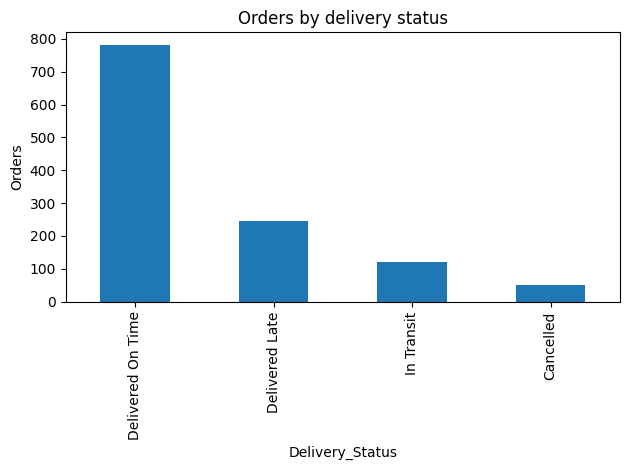

In [40]:
df["Delivery_Status"].value_counts().plot(kind="bar", title="Orders by delivery status")
plt.ylabel("Orders")
plt.tight_layout()
plt.show()

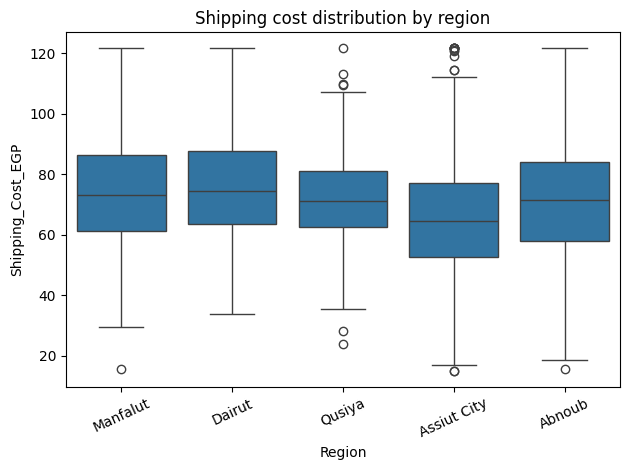

In [41]:
sns.boxplot(data=df, x="Region", y="Shipping_Cost_EGP")
plt.title("Shipping cost distribution by region")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [42]:
region_summary = delivered.groupby("Region", as_index=False).agg(
    On_Time_Rate=("SLA_Met","mean"),
    Orders=("Order_ID","count")
)
region_summary["On_Time_Rate"] *= 100
fig = px.bar(region_summary, x="Region", y="On_Time_Rate", color="Region",
             hover_data=["Orders"], title="On-time SLA by region")
fig.show()